# 01 - Dados: mosaico LROC WAC e catálogo de Robbins

**Objetivo:** conhecer os dados antes de detectar ou localizar qualquer coisa.

- **Mapa:** recorte do mosaico global LROC WAC (NASA/LRO), na região de lat −5° a 15° e lon 15° a 35°. Ele cobre a borda de Mare Tranquillitatis e as terras altas ao sul. O mapa de trabalho é reduzido para 0,2 km/px.
- **Gabarito:** catálogo de crateras de Robbins (2018), convertido de lat/lon/diâmetro para pixels do mapa.
- **Validação honesta:** a metade **oeste** do mapa é usada para *ajustar* parâmetros, e a metade **leste**, que o ajuste nunca vê, serve para *testar*.

In [1]:
import sys
sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import numpy as np

from pouso_lunar import config
from pouso_lunar.dados import carregar_gabarito, carregar_mapa
from pouso_lunar.geo import latlon_para_px

config.PASTA_RESULTADOS.mkdir(exist_ok=True)
mapa, info = carregar_mapa()
gab = carregar_gabarito(info)
print(f"mapa: {mapa.shape[1]} x {mapa.shape[0]} px, {info.km_por_px:.3f} km/px")
print(f"área: {mapa.shape[1] * info.km_por_px:.0f} x {mapa.shape[0] * info.km_por_px:.0f} km")
print(f"crateras no gabarito (diâmetro >= {config.DIAM_MIN_PX} px = {config.DIAM_MIN_PX * info.km_por_px:.1f} km): {len(gab)}")

mapa: 3033 x 3033 px, 0.200 km/px
área: 607 x 607 km
crateras no gabarito (diâmetro >= 10 px = 2.0 km): 1301


## O mapa e a divisão ajuste / teste

As **sombras** vêm do sol baixo das imagens do mosaico morfológico, e são elas que tornam as crateras visíveis para a detecção por gradiente. Ao norte fica o mar (basalto escuro e liso, com poucas crateras). Ao sul ficam as terras altas, claras e saturadas de crateras.

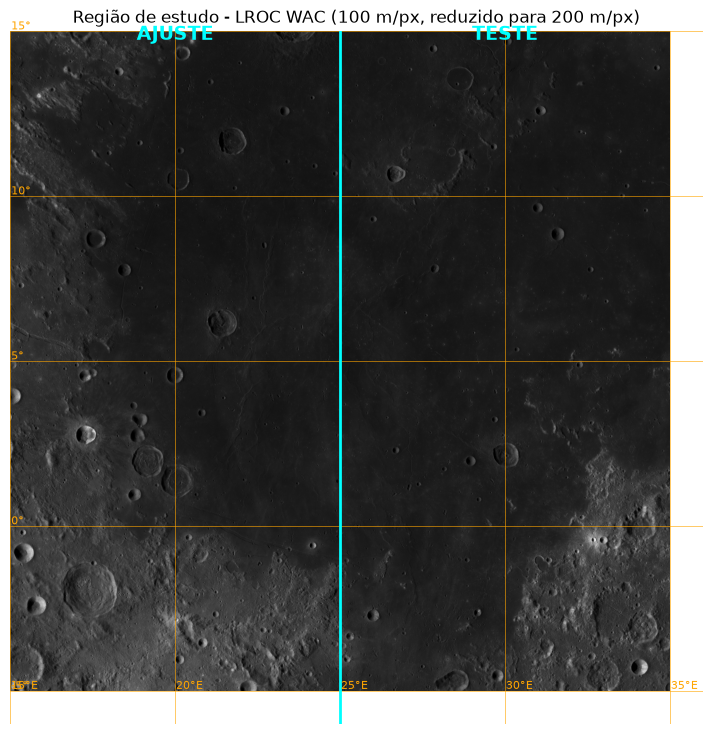

In [2]:
fig, ax = plt.subplots(figsize=(9, 9))
ax.imshow(mapa, cmap="gray")
for lat in range(-5, 16, 5):
    _, y = latlon_para_px(lat, config.LON_MIN, info)
    ax.axhline(y, color="orange", lw=0.6, alpha=0.7)
    ax.text(5, y - 8, f"{lat}°", color="orange", fontsize=8)
for lon in range(15, 36, 5):
    x, _ = latlon_para_px(config.LAT_MIN, lon, info)
    ax.axvline(x, color="orange", lw=0.6, alpha=0.7)
    ax.text(x + 4, mapa.shape[0] - 10, f"{lon}°E", color="orange", fontsize=8)
ax.axvline(info.largura / 2, color="cyan", lw=2)
ax.text(info.largura * 0.25, 40, "AJUSTE", color="cyan", ha="center", fontsize=14, weight="bold")
ax.text(info.largura * 0.75, 40, "TESTE", color="cyan", ha="center", fontsize=14, weight="bold")
ax.set_title("Região de estudo - LROC WAC (100 m/px, reduzido para 200 m/px)")
ax.axis("off")
fig.savefig(config.PASTA_RESULTADOS / "dados_mapa.png", dpi=110, bbox_inches="tight")
plt.show()

## Distribuição de tamanhos das crateras

A distribuição segue uma lei de potência: há muito mais crateras pequenas do que grandes. É por isso que o recall nas crateras pequenas pesa tanto na métrica global.

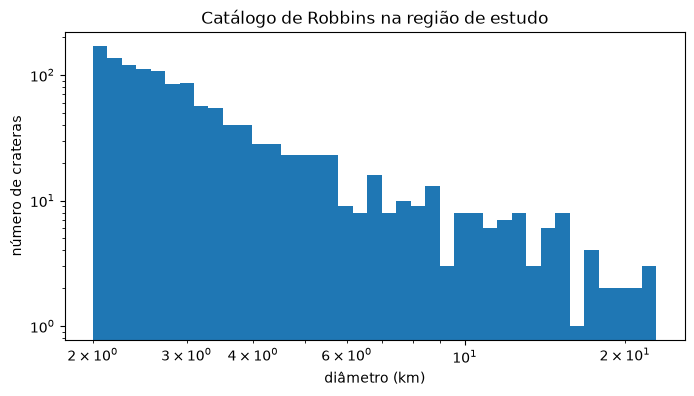

count    1301.00
mean        3.73
std         2.82
min         2.00
25%         2.28
50%         2.75
75%         3.78
max        22.91
Name: diam_km, dtype: float64


In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(gab["diam_km"], bins=np.logspace(np.log10(gab["diam_km"].min()), np.log10(gab["diam_km"].max()), 40))
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("diâmetro (km)"); ax.set_ylabel("número de crateras")
ax.set_title("Catálogo de Robbins na região de estudo")
fig.savefig(config.PASTA_RESULTADOS / "dados_hist_diametros.png", dpi=110, bbox_inches="tight")
plt.show()
print(gab["diam_km"].describe().round(2))

## De onde vem o sol?

O detector de sombra-brilho precisa saber de que lado fica a sombra. Para cada cratera do catálogo (metade de ajuste), comparamos o brilho médio das metades oeste/leste e norte/sul.

In [4]:
from pouso_lunar.dados import metade
lados = {"oeste": [], "leste": [], "norte": [], "sul": []}
for x, y, r in metade(gab[["x", "y", "r_px"]].to_numpy(), info, "ajuste"):
    x, y, r = int(x), int(y), int(r)
    if r < 6 or x - r < 0 or y - r < 0 or x + r >= info.largura or y + r >= info.altura:
        continue
    w = mapa[y - r:y + r + 1, x - r:x + r + 1].astype(float)
    lados["oeste"].append(w[:, :r].mean()); lados["leste"].append(w[:, r + 1:].mean())
    lados["norte"].append(w[:r].mean()); lados["sul"].append(w[r + 1:].mean())
for k, v in lados.items():
    print(f"brilho médio da metade {k}: {np.mean(v):.1f}")
frac = np.mean(np.array(lados["oeste"]) < np.array(lados["leste"]))
print(f"\nem {frac:.0%} das {len(lados['oeste'])} crateras a metade oeste é mais escura")
print("=> o sol vem do oeste: sombra a oeste, brilho a leste (config.DIRECAO_SOL_GRAUS = 0)")

brilho médio da metade oeste: 47.3
brilho médio da metade leste: 70.2
brilho médio da metade norte: 59.3
brilho médio da metade sul: 58.0

em 97% das 493 crateras a metade oeste é mais escura
=> o sol vem do oeste: sombra a oeste, brilho a leste (config.DIRECAO_SOL_GRAUS = 0)


## Conferindo o gabarito sobre a imagem

Se a conversão lat/lon → pixel estiver certa, os círculos do catálogo caem exatamente sobre as crateras da imagem.

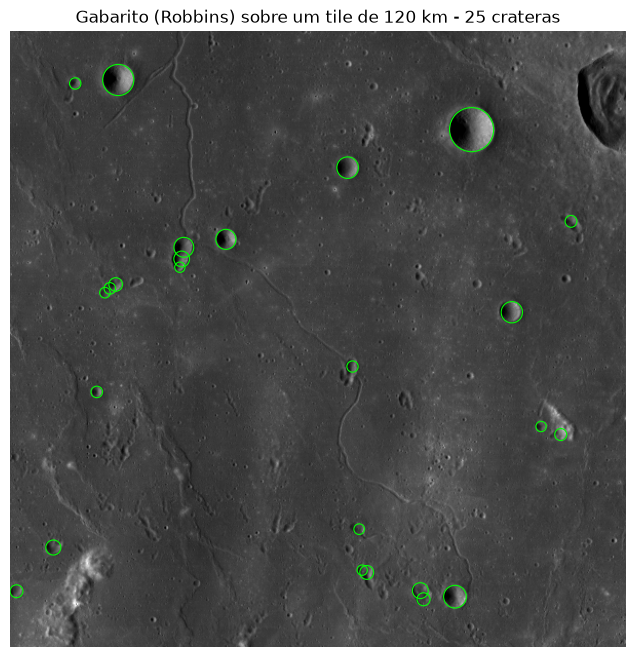

In [5]:
x0, y0, L = int(info.largura * 0.55), int(info.altura * 0.62), 600
tile = mapa[y0:y0 + L, x0:x0 + L]
sel = gab[(gab.x >= x0) & (gab.x < x0 + L) & (gab.y >= y0) & (gab.y < y0 + L)]
fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(tile, cmap="gray")
for _, c in sel.iterrows():
    ax.add_patch(plt.Circle((c.x - x0, c.y - y0), c.r_px, fill=False, color="lime", lw=0.8))
ax.set_title(f"Gabarito (Robbins) sobre um tile de {L * info.km_por_px:.0f} km - {len(sel)} crateras")
ax.axis("off")
fig.savefig(config.PASTA_RESULTADOS / "dados_tile_gabarito.png", dpi=110, bbox_inches="tight")
plt.show()